In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



In [2]:
datadir = "."

folders = ["train", "val", "test"]
categories = ["fractured", "not fractured"]

for folder in folders:
    print("\n", folder)

    for category in categories:
        path = os.path.join(datadir, folder, category)

        images = os.listdir(path)

        print(category, ":", len(images))



 train
fractured : 4606
not fractured : 4640

 val
fractured : 337
not fractured : 492

 test
fractured : 238
not fractured : 268


In [3]:

for folder in folders:
    print("\n", folder)

    total = 0

    for category in categories:
        path = os.path.join(datadir, folder, category)
        count = len(os.listdir(path))
        total += count

    for category in categories:
        path = os.path.join(datadir, folder, category)
        count = len(os.listdir(path))

        percentage = (count / total) * 100

        print(category, ":", round(percentage, 2), "%")



 train
fractured : 49.82 %
not fractured : 50.18 %

 val
fractured : 40.65 %
not fractured : 59.35 %

 test
fractured : 47.04 %
not fractured : 52.96 %


cleaning

In [4]:
for folder in folders:
    print("\n", folder)

    for category in categories:
        path = os.path.join(datadir, folder, category)

        corrupted_images = 0

        for img in os.listdir(path):
            img_path = os.path.join(path, img)

            image = cv2.imread(img_path)

            if image is None:
                corrupted_images += 1

        print(category, "corrupted images:", corrupted_images)



 train
fractured corrupted images: 0
not fractured corrupted images: 0

 val
fractured corrupted images: 0
not fractured corrupted images: 0

 test
fractured corrupted images: 0
not fractured corrupted images: 0


In [5]:

for folder in folders:
    print("\n", folder)

    for category in categories:
        path = os.path.join(datadir, folder, category)

        sizes = []

        for img in os.listdir(path):
            img_path = os.path.join(path, img)

            image = cv2.imread(img_path)

            if image is not None:
                sizes.append(image.shape)

        print(category, "number of images:", len(sizes))
        print("different image sizes:", len(set(sizes)))
        print("sample image size:", sizes[0])



 train
fractured number of images: 4606
different image sizes: 310
sample image size: (1024, 617, 3)
not fractured number of images: 4640
different image sizes: 47
sample image size: (2920, 2320, 3)

 val
fractured number of images: 337
different image sizes: 104
sample image size: (2928, 2328, 3)
not fractured number of images: 492
different image sizes: 18
sample image size: (2920, 2320, 3)

 test
fractured number of images: 238
different image sizes: 12
sample image size: (2928, 2328, 3)
not fractured number of images: 268
different image sizes: 15
sample image size: (2920, 2320, 3)


In [7]:
img_size = 60

training_data = []
validation_data = []
testing_data = []

for folder, data in [
    ("train", training_data),
    ("val", validation_data),
    ("test", testing_data)
]:
    for category in categories:

        path = os.path.join(datadir, folder, category)
        class_num = categories.index(category)

        for img in os.listdir(path):
            try:
                img_path = os.path.join(path, img)

                img_array = cv2.imread(img_path)

                new_array = cv2.resize(
                    img_array,
                    (img_size, img_size)
                )

                data.append([new_array, class_num])

            except Exception as e:
                pass

print("all images resized successfully")


all images resized successfully


In [8]:

print("training images:", len(training_data))
print("validation images:", len(validation_data))
print("testing images:", len(testing_data))

print("image shape:", training_data[0][0].shape)


training images: 9246
validation images: 829
testing images: 506
image shape: (60, 60, 3)


eda

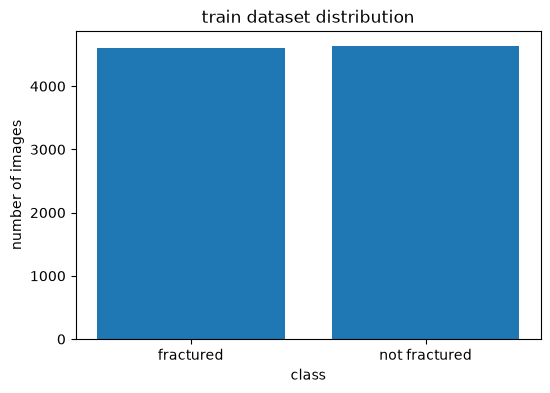

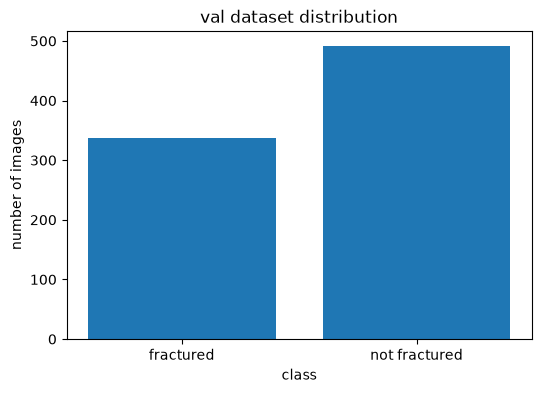

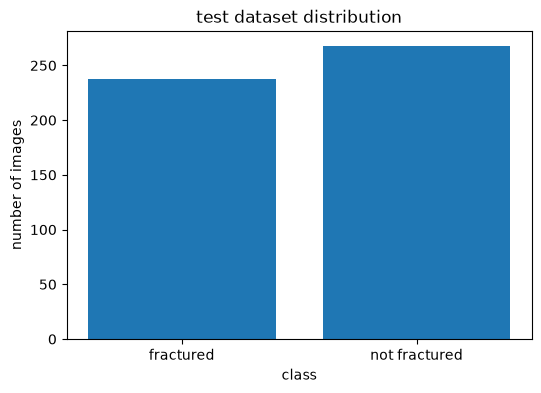

In [9]:

for folder in folders:

    counts = []

    for category in categories:
        path = os.path.join(datadir, folder, category)
        counts.append(len(os.listdir(path)))

    plt.figure(figsize=(6, 4))

    plt.bar(categories, counts)

    plt.title(folder + " dataset distribution")
    plt.xlabel("class")
    plt.ylabel("number of images")

    plt.show()


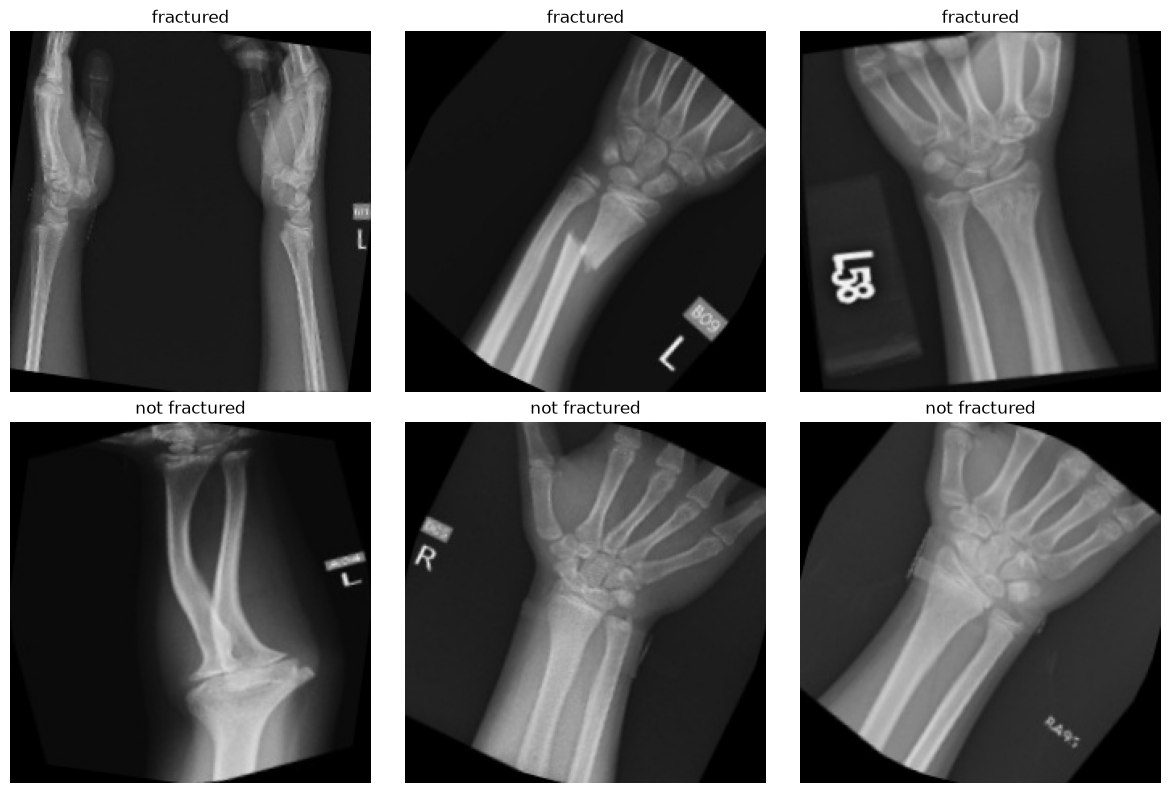

In [12]:
import random
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))
for i, category in enumerate(categories):

    path = os.path.join(datadir, "train", category)

    images = os.listdir(path)

    for j in range(3):

        img_name = random.choice(images)
        img_path = os.path.join(path, img_name)

        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        plt.subplot(2, 3, i * 3 + j + 1)
        plt.imshow(image)
        plt.title(category)
        plt.axis("off")

plt.tight_layout()
plt.show()


In [13]:

fractured_brightness = []
not_fractured_brightness = []

for image, label in training_data:

    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    brightness = np.mean(gray_image)

    if label == 0:
        fractured_brightness.append(brightness)
    else:
        not_fractured_brightness.append(brightness)

print("fractured average brightness:",
      round(np.mean(fractured_brightness), 2))

print("not fractured average brightness:",
      round(np.mean(not_fractured_brightness), 2))


fractured average brightness: 59.19
not fractured average brightness: 59.44


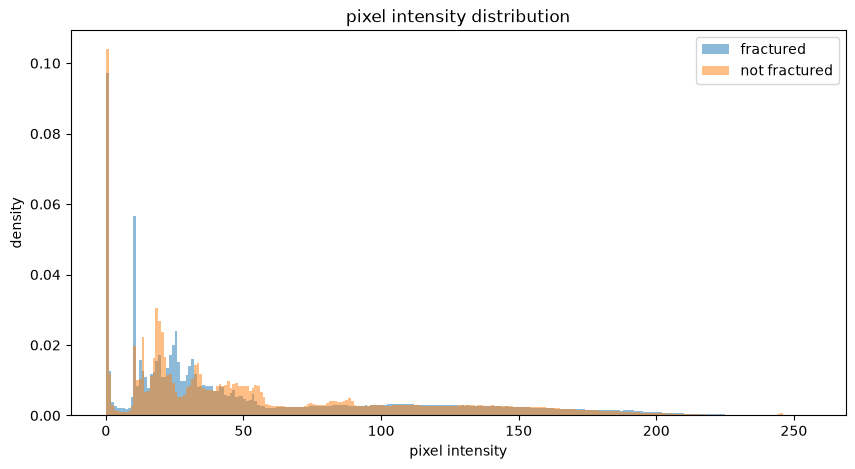

In [14]:

fractured_pixels = []
not_fractured_pixels = []

for image, label in training_data:

    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    if label == 0:
        fractured_pixels.append(gray_image.flatten())
    else:
        not_fractured_pixels.append(gray_image.flatten())

fractured_pixels = np.concatenate(fractured_pixels)
not_fractured_pixels = np.concatenate(not_fractured_pixels)

plt.figure(figsize=(10, 5))

plt.hist(
    fractured_pixels,
    bins=256,
    range=(0, 256),
    density=True,
    alpha=0.5,
    label="fractured"
)

plt.hist(
    not_fractured_pixels,
    bins=256,
    range=(0, 256),
    density=True,
    alpha=0.5,
    label="not fractured"
)

plt.title("pixel intensity distribution")
plt.xlabel("pixel intensity")
plt.ylabel("density")
plt.legend()

plt.show()


In [15]:

fractured_contrast = []
not_fractured_contrast = []

for image, label in training_data:

    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    contrast = np.std(gray_image)

    if label == 0:
        fractured_contrast.append(contrast)
    else:
        not_fractured_contrast.append(contrast)

print("fractured average contrast:",
      round(np.mean(fractured_contrast), 2))

print("not fractured average contrast:",
      round(np.mean(not_fractured_contrast), 2))


fractured average contrast: 54.54
not fractured average contrast: 50.66


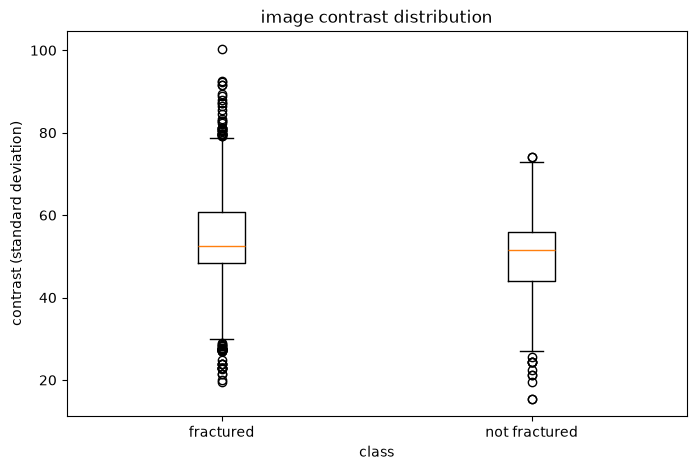

In [16]:

plt.figure(figsize=(8, 5))

plt.boxplot(
    [fractured_contrast, not_fractured_contrast],
    tick_labels=["fractured", "not fractured"]
)

plt.title("image contrast distribution")
plt.xlabel("class")
plt.ylabel("contrast (standard deviation)")

plt.show()


In [18]:
fractured_sharpness = []
not_fractured_sharpness = []

for image, label in training_data:

    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    sharpness = cv2.Laplacian(
        gray_image,
        cv2.CV_64F
    ).var()

    if label == 0:
        fractured_sharpness.append(sharpness)
    else:
        not_fractured_sharpness.append(sharpness)

print("fractured average sharpness:",
      round(np.mean(fractured_sharpness), 2))

print("not fractured average sharpness:",
      round(np.mean(not_fractured_sharpness), 2))

fractured average sharpness: 2476.91
not fractured average sharpness: 1836.08


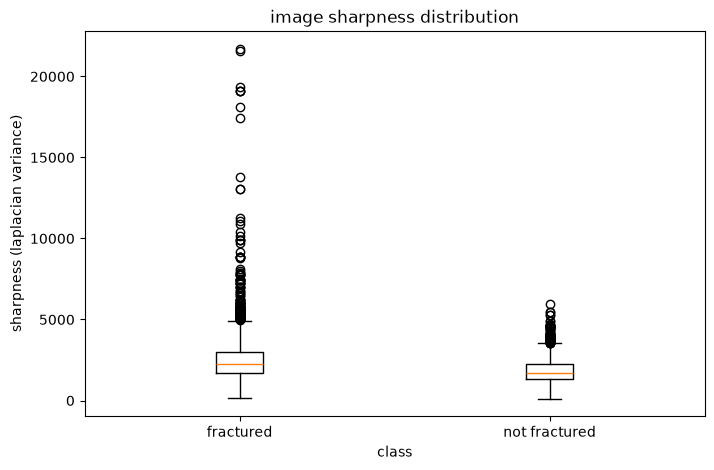

In [19]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [fractured_sharpness, not_fractured_sharpness],
    tick_labels=["fractured", "not fractured"]
)

plt.title("image sharpness distribution")
plt.xlabel("class")
plt.ylabel("sharpness (laplacian variance)")

plt.show()

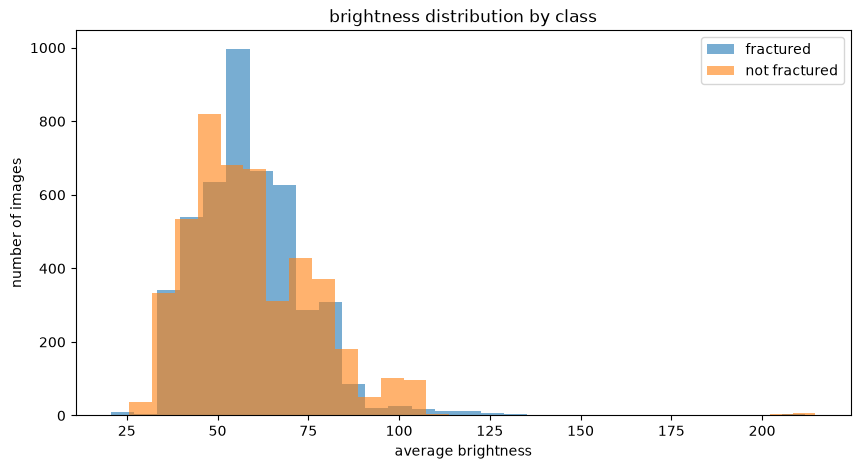

In [20]:
plt.figure(figsize=(10, 5))

plt.hist(
    fractured_brightness,
    bins=30,
    alpha=0.6,
    label="fractured"
)

plt.hist(
    not_fractured_brightness,
    bins=30,
    alpha=0.6,
    label="not fractured"
)

plt.title("brightness distribution by class")
plt.xlabel("average brightness")
plt.ylabel("number of images")
plt.legend()

plt.show()

In [21]:
blue_values = []
green_values = []
red_values = []

for image, label in training_data:

    blue_values.append(np.mean(image[:, :, 0]))
    green_values.append(np.mean(image[:, :, 1]))
    red_values.append(np.mean(image[:, :, 2]))

print("average blue intensity:", round(np.mean(blue_values), 2))
print("average green intensity:", round(np.mean(green_values), 2))
print("average red intensity:", round(np.mean(red_values), 2))

average blue intensity: 59.32
average green intensity: 59.32
average red intensity: 59.31


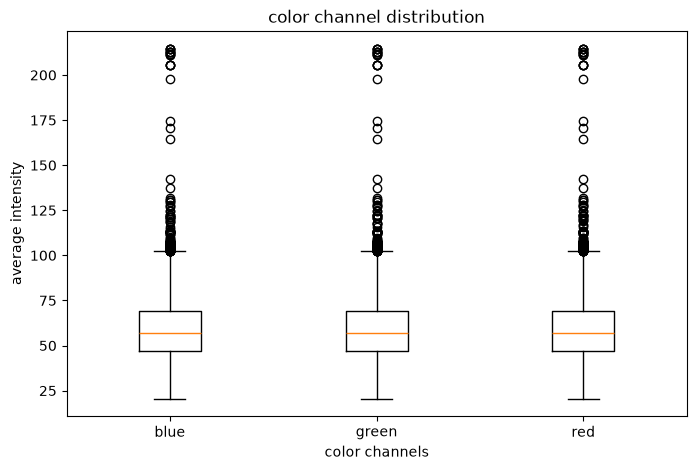

In [22]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [blue_values, green_values, red_values],
    tick_labels=["blue", "green", "red"]
)

plt.title("color channel distribution")
plt.xlabel("color channels")
plt.ylabel("average intensity")

plt.show()